# **Assignment Week 2 - Network Analysis**

For this assingment you will be working with Game of Thrones co-ocurrence network. The assignment is divided into three parts: Networks descriptive analyses, centrality measures, and community detection. 

**Importing the libraries**

In [33]:
import networkx as nx
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics

**Read the files:** *book1.csv*, *book2.csv*, *book3.csv*, *book4.csv*, *book5.csv*  in Week2/sample files/

In [ ]:
#Reading files
book1 = pd.read_csv('book1.csv')
book2 = pd.read_csv('book2.csv')  
book3 = pd.read_csv('book3.csv')
book4 = pd.read_csv('book4.csv')
book5 = pd.read_csv('book5.csv')

**Create five undirected weighted networks:** Create one network per book naming them got_1, got_2, got_3, got_4, and got_5. 

In [3]:
# Create your networks
nbook1=nx.from_pandas_edgelist(book1, source='Source', target='Target')
nbook2=nx.from_pandas_edgelist(book2, source='Source', target='Target')
nbook3=nx.from_pandas_edgelist(book3, source='Source', target='Target')
nbook4=nx.from_pandas_edgelist(book4, source='Source', target='Target')
nbook5=nx.from_pandas_edgelist(book5, source='Source', target='Target')


#### **Part 1: Game of thrones' networks descriptive analyses**

Inspect and compare the networks you have created. Which one is the biggest network? why? 

In [4]:
# Your code
nbooks=[nbook1,nbook2,nbook3,nbook4,nbook5]
for i,nb in enumerate (nbooks):
    print(f"Graph book {i+1}:")
    print(f" Number of nodes: {nb.number_of_nodes()}")
    print(f" Number of edges: {nb.number_of_edges()}")

Graph book 1:
 Number of nodes: 187
 Number of edges: 684
Graph book 2:
 Number of nodes: 259
 Number of edges: 775
Graph book 3:
 Number of nodes: 303
 Number of edges: 1008
Graph book 4:
 Number of nodes: 274
 Number of edges: 682
Graph book 5:
 Number of nodes: 317
 Number of edges: 760


#Your answer 
The biggest networks are book5 and book 3, they have the highest number of nodes and edges. This is probably because they cover more events and characters in the story, leading to more interactions.

In which of the five books are the characters better connected? why?

In [ ]:
nbooks=[nbook1,nbook2,nbook3,nbook4,nbook5]
densities=[]
avg_degrees=[]
for i, nb in enumerate(nbooks):
    #density
    density = nx.density(nb)
    densities.append(density)
    #average degree
    avg_degree = sum(dict(nb.degree()).values()) / nb.number_of_nodes()
    avg_degrees.append(avg_degree)
data_frame=pd.DataFrame({
    "Book": [f"Book {i+1}" for i in range(len(nbooks))],
    "Density": densities,
    "Average Degree": avg_degrees
})
data_frame

,Book,Density,Average Degree
0,Book 1,0.039331,7.315508
1,Book 2,0.023196,5.984556
2,Book 3,0.022031,6.653465
3,Book 4,0.018235,4.978102
4,Book 5,0.015174,4.794953


#Your answer
The book where the characters are better connected is book 1, as it has the highest average degree and density. This suggests that characters in this book interact more frequently with each other. Probabily because it acts as an introduction to the whole story, establishing many relationships among characters.

#### **Part 2: Centrality measures**

Which characters are the most influential in each book? why?

In [36]:
centrality_measures=[]
for i, nb in enumerate(nbooks):
    #highest degree node
    degrees = dict(nb.degree())
    max_degree_node = max(degrees, key=degrees.get)
    print(f"Graph book {i+1} highest degree node: {max_degree_node} with degree {degrees[max_degree_node]}")
    #highest closeness node
    closeness = nx.closeness_centrality(nb)
    max_closeness_node = max(closeness, key=closeness.get)
    print(f"Graph book {i+1} highest closeness node: {max_closeness_node} with closeness {closeness[max_closeness_node]}")
    #highest betweenness node
    betweenness = nx.betweenness_centrality(nb)
    max_betweenness_node = max(betweenness, key=betweenness.get)
    print(f"Graph book {i+1} highest betweenness node: {max_betweenness_node} with betweenness {betweenness[max_betweenness_node]}")
    #highest page rank node
    pagerank = nx.pagerank(nb)
    max_pagerank_node = max(pagerank, key=pagerank.get)
    print(f"Graph book {i+1} highest page rank node: {max_pagerank_node} with page rank {pagerank[max_pagerank_node]}")
    #add values in a list
    centrality_measures.append({
        'degree': max_degree_node,
        'closeness': max_closeness_node,
        'betweenness': max_betweenness_node,
        'pagerank': max_pagerank_node
    })

#dataframe of centrality measures
centrality_df = pd.DataFrame(centrality_measures, index=[f'book{i+1}' for i in range(len(nbooks))])
centrality_df

Graph book 1 highest degree node: Eddard-Stark with degree 66
Graph book 1 highest closeness node: Eddard-Stark with closeness 0.5636363636363636
Graph book 1 highest betweenness node: Eddard-Stark with betweenness 0.2696038913836117
Graph book 1 highest page rank node: Eddard-Stark with page rank 0.04550213151218522
Graph book 2 highest degree node: Tyrion-Lannister with degree 53
Graph book 2 highest closeness node: Robb-Stark with closeness 0.4777777777777778
Graph book 2 highest betweenness node: Arya-Stark with betweenness 0.1881116846731781
Graph book 2 highest page rank node: Tyrion-Lannister with page rank 0.028066681358075413
Graph book 3 highest degree node: Tyrion-Lannister with degree 59
Graph book 3 highest closeness node: Joffrey-Baratheon with closeness 0.4740973312401884
Graph book 3 highest betweenness node: Jon-Snow with betweenness 0.2238286056882584
Graph book 3 highest page rank node: Tyrion-Lannister with page rank 0.02381979111500957
Graph book 4 highest degree n

,degree,closeness,betweenness,pagerank
book1,Eddard-Stark,Eddard-Stark,Eddard-Stark,Eddard-Stark
book2,Tyrion-Lannister,Robb-Stark,Arya-Stark,Tyrion-Lannister
book3,Tyrion-Lannister,Joffrey-Baratheon,Jon-Snow,Tyrion-Lannister
book4,Jaime-Lannister,Cersei-Lannister,Stannis-Baratheon,Jaime-Lannister
book5,Jon-Snow,Stannis-Baratheon,Stannis-Baratheon,Jon-Snow


#Your answer
The most influential characters in the first book is eddard-stark, as he has the highest degree centrality, betweenness centrality, and closeness centrality.
The most influential character in the second book is tyrion-lannister, as he has the highest page rank and degree .
The most influential character in the third book is Tyrion Lannister, as he has the highest page rank and degree.
The most influential character in the fourth book is Jaime Lannister, as he has the highest degree and page rank.
The most influential character in the fifth book is Jon Snow and Stannis Baratheon, as they are both the best in two centrality measures.

Select your two favourite and your two least favourite characters in the series. Analyse and compare their centrality measures throughout the five books.

In [38]:
favourite_characters= ['Jon-Snow', 'Daenerys-Targaryen']
unfavourite_characters= ['Tyrion-Lannister', 'Cersei-Lannister']

characters_of_interest = favourite_characters + unfavourite_characters
rows = []
for ch in characters_of_interest:
    for i, G in enumerate(nbooks, start=1):

        if ch not in G:
            # Add a row indicating absence in the network
            rows.append({
                "character": ch,
                "book": i,
                "degree": None,
                "betweenness": None,
                "closeness": None,
                "eigenvector": None,
                "pagerank": None
            })
            continue

        # Compute centralities for this book
        degree_c = nx.degree_centrality(G)
        betweenness_c = nx.betweenness_centrality(G)
        closeness_c = nx.closeness_centrality(G)
        eigenvector_c = nx.eigenvector_centrality(G, max_iter=1000)
        pagerank_c = nx.pagerank(G)

        # Append to list
        rows.append({
            "character": ch,
            "book": i,
            "degree": degree_c[ch],
            "betweenness": betweenness_c[ch],
            "closeness": closeness_c[ch],
            "eigenvector": eigenvector_c[ch],
            "pagerank": pagerank_c[ch]
        })

# Convert to DataFrame
df = pd.DataFrame(rows)
df

,character,book,degree,betweenness,closeness,eigenvector,pagerank
0,Jon-Snow,1,0.198925,0.171581,0.493369,0.170460,0.026841
1,Jon-Snow,2,0.108527,0.174440,0.396923,0.073837,0.018773
2,Jon-Snow,3,0.172185,0.223829,0.433908,0.105068,0.023599
3,Jon-Snow,4,0.040293,0.065803,0.335381,0.054211,0.007734
4,Jon-Snow,5,0.196203,0.244849,0.355056,0.190785,0.037934
5,Daenerys-Targaryen,1,0.112903,0.086270,0.405229,0.047389,0.014702
6,Daenerys-Targaryen,2,0.069767,0.082876,0.324121,0.016655,0.015477
7,Daenerys-Targaryen,3,0.079470,0.136491,0.326840,0.014904,0.015272
8,Daenerys-Targaryen,4,NaN,NaN,NaN,NaN,NaN
9,Daenerys-Targaryen,5,0.183544,0.295946,0.364055,0.402645,0.032758


How do their centralities relate to their role in the series development?

#Your answer
The centrality values reflect how involved each character is in the story and how many connections they have within the narrative. Characters with high centrality tend to interact with many others, influence different plotlines, or act as bridges between groups.

Jon Snow shows a pattern of growing importance. His centrality increases especially in later books, reflecting his expanding leadership role and involvement in the final events.

Daenerys Targaryen starts with moderate centrality, then becomes highly central later on, especially in the fifth book. This matches her rise in power and the growing complexity of her storyline.

Tyrion Lannister maintains consistently high centrality across all books. This indicates he is continuously connected to many characters and central to political and social developments.

Cersei Lannister has moderate centrality early on, peaks strongly in the fourth book, and then decreases. This aligns with her rise to political power followed by her decline.

#### **Part 3: Community detection**

Select your favourite book and implement the three community detection algoritms covered in the lecture. 

In [ ]:
# Girvan Newman
gn_communities = list(nx.community.greedy_modularity_communities(nbook1))

# Louvain
louvain_communities = nx.community.louvain_communities(nbook1)

#Label propagation
lp_communities = list(nx.community.label_propagation_communities(nbook1))

How many communities are identified by each algorithm?

In [19]:
#number of communities Girvan Newman
print(f"Girvan Newman number of communities: {len(gn_communities)}")
#number of communities Louvain
print(f"Louvain number of communities: {len(louvain_communities)}")
#number of communities Label Propagation
print(f"Label Propagation number of communities: {len(lp_communities)}")

Girvan Newman number of communities: 7
Louvain number of communities: 8
Label Propagation number of communities: 9


Plot three networks colouring the nodes based on the communitity the characters were assigned to by each algorithm. <br> *Hint: you can make some modifications to make the plots to look better*

C:\Users\Utente\AppData\Local\Temp\ipykernel_20936\3348222879.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab10", len(communities))


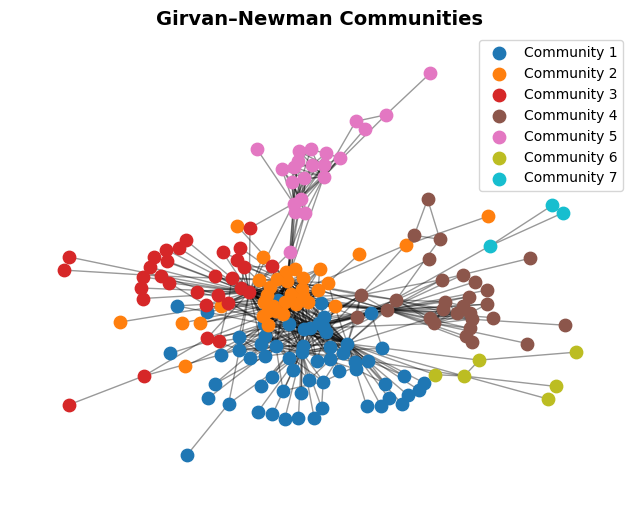

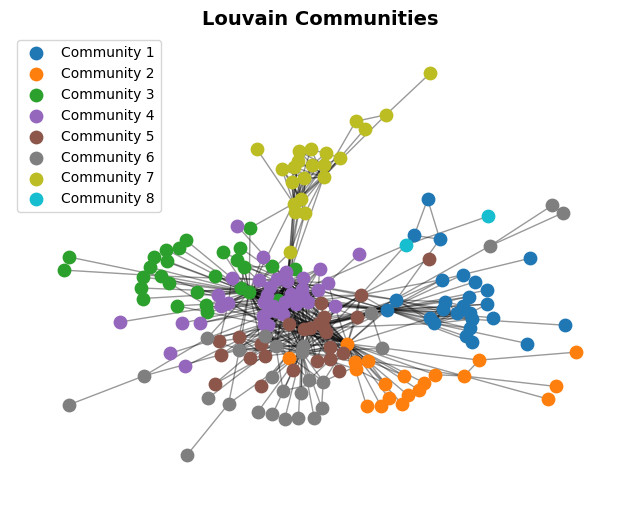

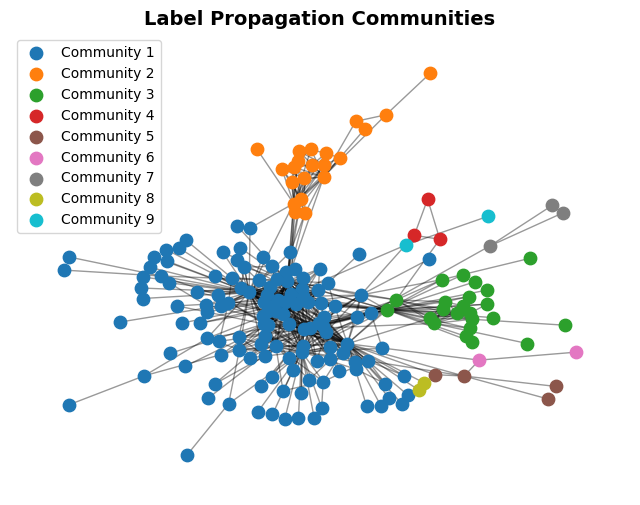

In [ ]:
import matplotlib.cm as cm
#plot communities
def plot_communities(G, communities, title, figsize=(8,6)):
    pos = nx.spring_layout(G, seed=42)        
    plt.figure(figsize=figsize)

    # Create a colormap with colors related to communities
    cmap = cm.get_cmap("tab10", len(communities))

    for i, community in enumerate(communities):
        nx.draw_networkx_nodes(
            G, pos,
            nodelist=list(community),

            node_size=80,
            node_color=[cmap(i)],
            label=f"Community {i+1}"
        )

    # Draw edges
    nx.draw_networkx_edges(G, pos, alpha=0.4)

    plt.title(title, fontsize=14, fontweight="bold")
    plt.legend(scatterpoints=1, fontsize=10)
    plt.axis('off')
    plt.show()
    
plot_communities(nbook1, gn_communities,      "Girvan–Newman Communities")
plot_communities(nbook1, louvain_communities, "Louvain Communities")
plot_communities(nbook1, lp_communities,      "Label Propagation Communities")


C:\Users\Utente\AppData\Local\Temp\ipykernel_20936\3348222879.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab10", len(communities))


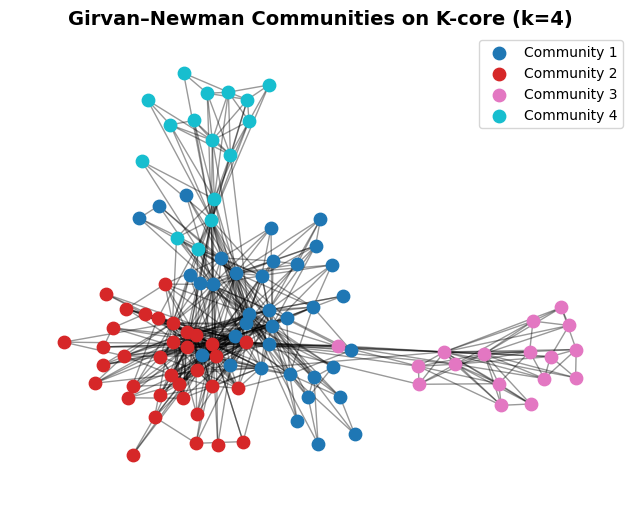

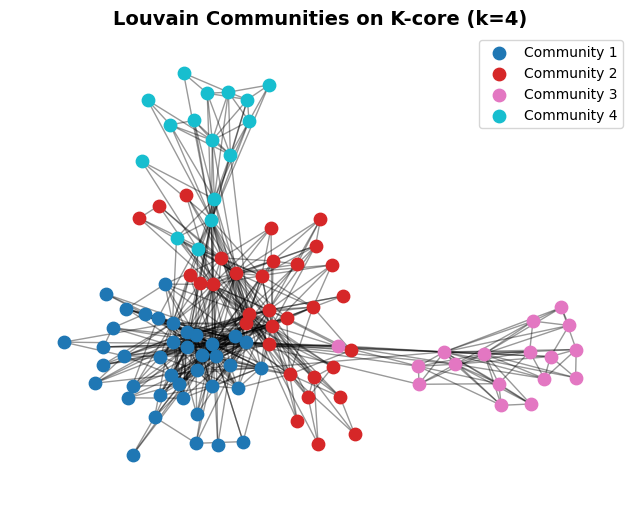

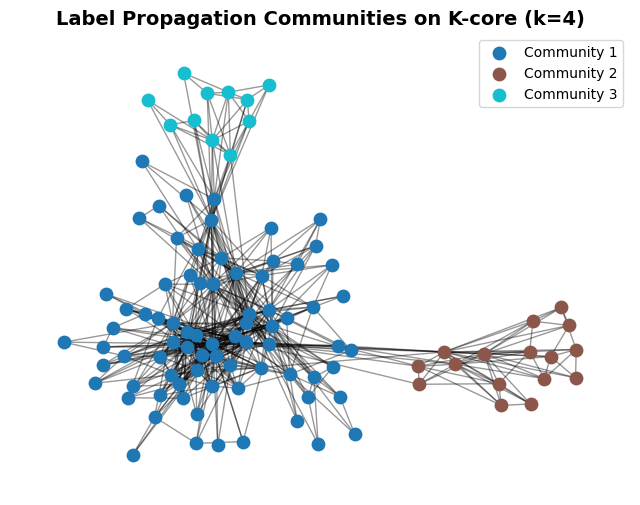

In [ ]:
K_core_graph = nx.k_core(nbook1, k=3)
# Girvan Newman
core_newman = list(nx.community.greedy_modularity_communities(K_core_graph))
# Louvain
core_louvain = list(nx.community.louvain_communities(K_core_graph, weight='weight'))
#Label propagation
core_lpa = list(nx.community.asyn_lpa_communities(K_core_graph, weight='weight'))

plot_communities(K_core_graph, core_newman,      "Girvan–Newman Communities on K-core (k=3)")
plot_communities(K_core_graph, core_louvain,     "Louvain Communities on K-core (k=3)")
plot_communities(K_core_graph, core_lpa,         "Label Propagation Communities on K-core (k=3)")

Compare the communities identified by each algorithm. Which one has the highest modularity? How similar or different are they?

In [ ]:
from sklearn.metrics.cluster import normalized_mutual_info_score
# comparation between algorithms modularity
for alg, communities in [("Girvan-Newman", gn_communities), ("Louvain", louvain_communities), ("Label Propagation", lp_communities)]:
    modularity = nx.community.modularity(nbook1, communities)
    print(f"{alg} Modularity: {modularity:.4f}")

algorithms = {
    "Girvan-Newman": gn_communities,
    "Louvain": louvain_communities,
    "Label Propagation": lp_communities
}
# Convert communities to labels
def to_labels(G, comms):
    lbl = {}
    for i, c in enumerate(comms):
        for n in c:
            lbl[n] = i
    return [lbl[n] for n in G.nodes()]

# Precompute labels
labels = {name: to_labels(nbook1, comms) for name, comms in algorithms.items()}

# NMI similarities
print("\nNMI similarities:")
names = list(labels.keys())
for i in range(len(names)):
    for j in range(i+1, len(names)):
        nmi = normalized_mutual_info_score(labels[names[i]], labels[names[j]])
        print(f"{names[i]} vs {names[j]}: {nmi:.4f}")
   

Girvan-Newman Modularity: 0.4744
Louvain Modularity: 0.4845
Label Propagation Modularity: 0.3115

NMI similarities:
Girvan-Newman vs Louvain: 0.7045
Girvan-Newman vs Label Propagation: 0.6345
Louvain vs Label Propagation: 0.5742


#Your answer
The Louvain algorithm has the highest modularity indicating it found the most distinct communities. The Girvan-Newman has a similar modularity while Label Propagation has the lowest modularity, suggesting less distinct communities.

Between these methods, Louvain and Girvan-Newman have the highest NMI similarity, indicating they produce more similar community structures. Label Propagation differs more significantly from the other two methods.

